In [1]:
import sys
import os
sys.path.append(os.getcwd())
import torch
import numpy as np
import cv2
import math
import imageio
import argparse
import json
from tqdm import tqdm
from simple_waymo_open_dataset_reader import WaymoDataFileReader
from simple_waymo_open_dataset_reader import dataset_pb2, label_pb2
from simple_waymo_open_dataset_reader import utils
from lib.utils.box_utils import bbox_to_corner3d, get_bound_2d_mask
from lib.utils.img_utils import draw_3d_box_on_img
from lib.utils.graphics_utils import project_numpy

import glob
import matplotlib.pyplot as plt
from lib.utils.img_utils import visualize_depth_numpy

# camera_names_dict = {
#     dataset_pb2.CameraName.FRONT_LEFT: 'FRONT_LEFT', 
#     dataset_pb2.CameraName.FRONT_RIGHT: 'FRONT_RIGHT',
#     dataset_pb2.CameraName.FRONT: 'FRONT', 
#     dataset_pb2.CameraName.SIDE_LEFT: 'SIDE_LEFT',
#     dataset_pb2.CameraName.SIDE_RIGHT: 'SIDE_RIGHT',
# }

# image_heights = [1280, 1280, 1280, 886, 886]
# image_widths = [1920, 1920, 1920, 1920, 1920]

# laser_names_dict = {
#     dataset_pb2.LaserName.TOP: 'TOP',
#     dataset_pb2.LaserName.FRONT: 'FRONT',
#     dataset_pb2.LaserName.SIDE_LEFT: 'SIDE_LEFT',
#     dataset_pb2.LaserName.SIDE_RIGHT: 'SIDE_RIGHT',
#     dataset_pb2.LaserName.REAR: 'REAR',
# }

# opencv2camera = np.array([[0., 0., 1., 0.],
#                         [-1., 0., 0., 0.],
#                         [0., -1., 0., 0.],
#                         [0., 0., 0., 1.]])



In [2]:
def get_extrinsic(camera_calibration):
    camera_extrinsic = np.array(camera_calibration.extrinsic.transform).reshape(4, 4) # camera to vehicle
    extrinsic = np.matmul(camera_extrinsic, opencv2camera) # [forward, left, up] to [right, down, forward]
    return extrinsic
    
def get_intrinsic(camera_calibration):
    camera_intrinsic = camera_calibration.intrinsic
    fx = camera_intrinsic[0]
    fy = camera_intrinsic[1]
    cx = camera_intrinsic[2]
    cy = camera_intrinsic[3]
    intrinsic = np.array([[fx, 0, cx],[0, fy, cy],[0, 0, 1]])
    return intrinsic

def project_label_to_image(dim, obj_pose, calibration):
    bbox_l, bbox_w, bbox_h = dim
    bbox = np.array([[-bbox_l, -bbox_w, -bbox_h], [bbox_l, bbox_w, bbox_h]]) * 0.5
    points = bbox_to_corner3d(bbox)
    points = np.concatenate([points, np.ones_like(points[..., :1])], axis=-1)
    points_vehicle = points @ obj_pose.T # 3D bounding box in vehicle frame
    extrinsic = get_extrinsic(calibration)
    intrinsic = get_intrinsic(calibration)
    width, height = calibration.width, calibration.height
    points_uv, valid = project_numpy(
        xyz=points_vehicle[..., :3], 
        K=intrinsic, 
        RT=np.linalg.inv(extrinsic), 
        H=height, W=width
    )
    return points_uv, valid

def project_label_to_mask(dim, obj_pose, calibration):
    bbox_l, bbox_w, bbox_h = dim
    bbox = np.array([[-bbox_l, -bbox_w, -bbox_h], [bbox_l, bbox_w, bbox_h]]) * 0.5
    points = bbox_to_corner3d(bbox)
    points = np.concatenate([points, np.ones_like(points[..., :1])], axis=-1)
    points_vehicle = points @ obj_pose.T # 3D bounding box in vehicle frame
    extrinsic = get_extrinsic(calibration)
    intrinsic = get_intrinsic(calibration)
    width, height = calibration.width, calibration.height
    mask = get_bound_2d_mask(
        corners_3d=points_vehicle[..., :3],
        K=intrinsic,
        pose=np.linalg.inv(extrinsic), 
        H=height, W=width
    )
    
    return mask

def inbbox_points(points, corner3d):
    min_xyz = corner3d[0]
    max_xyz = corner3d[-1]
    return np.logical_and(
        np.all(points >= min_xyz, axis=-1),
        np.all(points <= max_xyz, axis=-1)
    )



In [3]:
def load_calibrations(data_path, start_timestep, end_timestep):
    """
    Load the calibration files of the dataset.
    e.g., lidar to world transformation matrices.
    """
    # Note that in the Waymo Open Dataset, the lidar coordinate system is the same
    # as the vehicle coordinate system
    lidar_to_worlds = []

    # we tranform the poses w.r.t. the first timestep to make the origin of the
    # first ego pose as the origin of the world coordinate system.
    ego_to_world_start = np.loadtxt(
        os.path.join(data_path, "ego_pose", f"{start_timestep:03d}.txt")
    )
    for t in range(start_timestep, end_timestep):
        ego_to_world_current = np.loadtxt(
            os.path.join(data_path, "ego_pose", f"{t:03d}.txt")
        )
        # compute ego_to_world transformation
        lidar_to_world = np.linalg.inv(ego_to_world_start) @ ego_to_world_current
        lidar_to_worlds.append(lidar_to_world)

#     self.lidar_to_worlds = torch.from_numpy(
#         np.stack(lidar_to_worlds, axis=0)
#     ).float()

    return np.stack(lidar_to_worlds, axis=0)
        


def load_lidar(lidar_filepaths, ):
    """
    Load the lidar data of the dataset from the filelist.
    """
    origins, directions, ranges, laser_ids = [], [], [], []
    # flow/ground info are used for evaluation only
    flows, flow_classes, grounds = [], [], []
    # in waymo, we simplify timestamps as the time indices
    timesteps = []

    accumulated_num_original_rays = 0
    accumulated_num_rays = 0
    for t in trange(
        0, len(lidar_filepaths), desc="Loading lidar", dynamic_ncols=True
    ):
        # each lidar_info contains an Nx14 array
        # from left to right:
        # origins: 3d, points: 3d, flows: 3d, flow_class: 1d,
        # ground_labels: 1d, intensities: 1d, elongations: 1d, laser_ids: 1d
        lidar_info = np.memmap(
            lidar_filepaths[t],
            dtype=np.float32,
            mode="r",
        ).reshape(-1, 14)
        original_length = len(lidar_info)
        accumulated_num_original_rays += original_length

#         # select lidar points based on the laser id
#         if self.data_cfg.only_use_top_lidar:
#             # laser_ids: 0: TOP, 1: FRONT, 2: SIDE_LEFT, 3: SIDE_RIGHT, 4: REAR
#             lidar_info = lidar_info[lidar_info[:, 13] == 0]

        lidar_origins = lidar_info[:, :3].float()
        lidar_points = lidar_info[:, 3:6].float()
        lidar_ids = lidar_info[:, 13].float()
        lidar_flows = lidar_info[:, 6:9].float()
        lidar_flow_classes = lidar_info[:, 9].long()
        ground_labels = lidar_info[:, 10].long()
        # we don't collect intensities and elongations for now

        # select lidar points based on a truncated ego-forward-directional range
        # this is to make sure most of the lidar points are within the range of the camera
        valid_mask = torch.ones_like(lidar_origins[:, 0]).bool()
            
        # 从config读取：
        truncated_max_range = 80 # max range for truncated lidar in a ego-centric coordinate system
        truncated_min_range = -2 
        
        if truncated_max_range is not None:
            valid_mask = lidar_points[:, 0] < truncated_max_range
        if truncated_min_range is not None:
            valid_mask = valid_mask & (
                lidar_points[:, 0] > truncated_min_range
            )
        lidar_origins = lidar_origins[valid_mask]
        lidar_points = lidar_points[valid_mask]
        lidar_ids = lidar_ids[valid_mask]
        lidar_flows = lidar_flows[valid_mask]
        lidar_flow_classes = lidar_flow_classes[valid_mask]
        ground_labels = ground_labels[valid_mask]
        # transform lidar points from lidar coordinate system to world coordinate system
        lidar_origins = (
            self.lidar_to_worlds[t][:3, :3] @ lidar_origins.T
            + self.lidar_to_worlds[t][:3, 3:4]
        ).T
        lidar_points = (
            self.lidar_to_worlds[t][:3, :3] @ lidar_points.T
            + self.lidar_to_worlds[t][:3, 3:4]
        ).T
        # scene flows are in the lidar coordinate system, so we need to rotate them
        lidar_flows = (self.lidar_to_worlds[t][:3, :3] @ lidar_flows.T).T
        # compute lidar directions
        lidar_directions = lidar_points - lidar_origins
        lidar_ranges = torch.norm(lidar_directions, dim=-1, keepdim=True)
        lidar_directions = lidar_directions / lidar_ranges
        # we use time indices as the timestamp for waymo dataset
        lidar_timestamp = torch.ones_like(lidar_ranges).squeeze(-1) * t
        accumulated_num_rays += len(lidar_ranges)

        origins.append(lidar_origins)
        directions.append(lidar_directions)
        ranges.append(lidar_ranges)
        laser_ids.append(lidar_ids)
        flows.append(lidar_flows)
        flow_classes.append(lidar_flow_classes)
        grounds.append(ground_labels)
        # we use time indices as the timestamp for waymo dataset
        timesteps.append(lidar_timestamp)

    logger.info(
        f"Number of lidar rays: {accumulated_num_rays} "
        f"({accumulated_num_rays / accumulated_num_original_rays * 100:.2f}% of "
        f"{accumulated_num_original_rays} original rays)"
    )
    logger.info("Filter condition:")
    logger.info(f"  only_use_top_lidar: {self.data_cfg.only_use_top_lidar}")
    logger.info(f"  truncated_max_range: {self.data_cfg.truncated_max_range}")
    logger.info(f"  truncated_min_range: {self.data_cfg.truncated_min_range}")

    self.origins = torch.cat(origins, dim=0)
    self.directions = torch.cat(directions, dim=0)
    self.ranges = torch.cat(ranges, dim=0)
    self.laser_ids = torch.cat(laser_ids, dim=0)
    self.visible_masks = torch.zeros_like(self.ranges).squeeze().bool()
    self.colors = torch.ones_like(self.directions)
    # becasue the flows here are velocities (m/s), and the fps of the lidar is 10,
    # we need to divide the velocities by 10 to get the displacements/flows
    # between two consecutive lidar scans
    self.flows = torch.cat(flows, dim=0) / 10.0
    self.flow_classes = torch.cat(flow_classes, dim=0)
    self.grounds = torch.cat(grounds, dim=0).bool()

    # the underscore here is important.
    self._timesteps = torch.cat(timesteps, dim=0)
    self.register_normalized_timestamps()



In [89]:
#  Nuscenes 仅考虑Dataloader部分读取
data_path = "/home/zyk/Projects/_DL/_Reconstruction/drivestudio/data/nuscenes/processed_10Hz/mini/003"
colmap_basedir = os.path.join(f'/home/zyk/Projects/_DL/_Reconstruction/street_gaussians_new_start/output/waymo_full_exp_origin/0709_ds_nuscenes03/colmap')


lidar_ds_path = os.path.join(data_path, "lidar/*.bin")
lidar_filepaths = sorted(glob.glob(lidar_ds_path))

from tqdm import trange, tqdm


# 开始
# def load_lidar(lidar_filepaths, ):

origins, directions, ranges = [], [], []
points = []

timesteps = []

accumulated_num_original_rays = 0
accumulated_num_rays = 0

start_timestep = 0

for t in trange(
    0, len(lidar_filepaths), desc="Loading lidar", dynamic_ncols=True
):
    lidar_info = np.fromfile(lidar_filepaths[t], dtype=np.float32).reshape(-1, 4)
     
    original_length = len(lidar_info)
    accumulated_num_original_rays += original_length

    lidar_points = lidar_info[:, :3]
    lidar_origins = np.zeros_like(lidar_points)

    
    camera_front_start = np.loadtxt(
        os.path.join(data_path, "extrinsics", f"{start_timestep:03d}_0.txt")
    )
    pose_file = os.path.join(data_path, "lidar_pose", f"{t:03d}.txt")
    
    lidar_to_world = np.loadtxt(pose_file)
    lidar_to_world = np.linalg.inv(camera_front_start) @ lidar_to_world
    
    lidar_origins = (
        lidar_to_world[:3, :3] @ lidar_origins.T
        + lidar_to_world[:3, 3:4]
    ).T
    lidar_points = (
        lidar_to_world[:3, :3] @ lidar_points.T
        + lidar_to_world[:3, 3:4]
    ).T
    lidar_directions = lidar_points - lidar_origins
    lidar_ranges = np.linalg.norm(lidar_directions, axis=-1, keepdims=True)
    lidar_directions = lidar_directions / lidar_ranges
    lidar_timestamp = np.ones_like(lidar_ranges).squeeze(-1) * t
    accumulated_num_rays += len(lidar_ranges)

    origins.append(lidar_origins)
    points.append(lidar_points)
    directions.append(lidar_directions)
    ranges.append(lidar_ranges)
    timesteps.append(lidar_timestamp)

origins = np.concatenate(origins, axis=0)
points = np.concatenate(points, axis=0)

directions = np.concatenate(directions, axis=0)
ranges = np.concatenate(ranges, axis=0)
visible_masks = np.zeros_like(ranges).astype(np.bool_)
colors = np.ones_like(directions)

# the underscore here is important.
_timesteps = np.concatenate(timesteps, axis=0)
# register_normalized_timestamps()


Loading lidar: 100%|█| 201/201 [00:00<00:00, 491.44it/


In [ ]:
# import open3d as o3d
# world_origin = o3d.geometry.PointCloud()
# world_origin.points = o3d.utility.Vector3dVector(points)
# world_origin.colors = o3d.utility.Vector3dVector(colors)

# o3d.visualization.draw_geometries([world_origin])


In [123]:
# cameras = [0,1,2,3,4,5]
cameras = [0,1,2,3,4]
OPENCV2DATASET = np.array(
    [[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]]
)
# LIDAR_TRANS = np.array(
#     [[0, -1, 0], [1, 0, 0], [0, 0, 1]]
# )
LIDAR_TRANS = np.array(
    [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
)


WIDTH  = 1600 #// 2
HEIGHT = 900 #// 2

points = []
colors = []

# def project_lidar_pts_on_images(self, delete_out_of_view_points=True):

camera_front_start = np.loadtxt(
    os.path.join(data_path, "extrinsics", f"{start_timestep:03d}_0.txt")
)

pts_3d_all = dict() # local 坐标下，可包含cam未观测视角
pts_2d_all = dict()

for t in tqdm(
    range(len(lidar_filepaths)), 
#     range(50),
#     desc="Projecting lidar pts on images for camera {}".format(cam),
    dynamic_ncols=True
):
#     t = 150
    
    frame_idx = t
    pts_3d = [] # LiDAR point cloud in world frame
    pts_2d = [] # LiDAR point cloud projection in camera [camera_name, w, h] 
    
    ################## LIDAR coordinate ########################
    lidar_to_world = np.loadtxt(
        os.path.join(data_path, "lidar_pose", f"{t:03d}.txt")
    )
    # compute ego_to_world transformation
    lidar_to_world = np.linalg.inv(camera_front_start) @ lidar_to_world
    
    lidar_info = np.fromfile(lidar_filepaths[t], dtype=np.float32).reshape(-1, 4)
    local_lidar_points = lidar_info[:, :3]
    dist = np.linalg.norm(local_lidar_points[:,:2], axis=1)
    local_lidar_points = local_lidar_points[dist > 2.5] # 车身遮挡必须过滤。先按半车长2.5m计算
    
    # 线扫雷达扫到车身需要剔除
    EGOSIZE = 6
    local_lidar_points = local_lidar_points[(np.linalg.norm(local_lidar_points, axis=1) > EGOSIZE / 2),:3] 
    
    camera_projection = np.zeros([local_lidar_points.shape[0], 6]).astype(np.int16)
    camera_projection[:,0] = -1
    camera_projection[:,3] = -1
    
    global_lidar_points = (
        lidar_to_world[:3, :3] @ local_lidar_points.T
        + lidar_to_world[:3, 3:4] 
    ).T
#     ############################################
#     local_lidar_points = local_lidar_points @ LIDAR_TRANS
    
    pts_3d.append(local_lidar_points)
    
    
    for cam_id in cameras:
        image = plt.imread(os.path.join(data_path, "images", f"{t:03d}_{cam_id}.jpg"))
#         image = image[::2, ::2, :]
        
        intrinsic = np.loadtxt(
            os.path.join(data_path, "intrinsics", f"{cam_id}.txt")
        )
        
        fx, fy, cx, cy = intrinsic[0], intrinsic[1], intrinsic[2], intrinsic[3]
        k1, k2, p1, p2, k3 = intrinsic[4], intrinsic[5], intrinsic[6], intrinsic[7], intrinsic[8]

#         fx /= 2
#         fy /= 2
#         cx /= 2
#         cy /= 2
        
        intrinsic_4x4 = np.zeros([4,4])
        intrinsic_4x4[:3, :3] = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]])
        intrinsic_4x4[3, 3] = 1.0

        
        cam2world = np.loadtxt(
            os.path.join(data_path, "extrinsics", f"{t:03d}_{cam_id}.txt")
        )

        # Align camera poses with the first camera pose
        cam2world = np.linalg.inv(camera_front_start) @ cam2world
#         cam2world = cam2world @ OPENCV2DATASET

        lidar2img = intrinsic_4x4 @ np.linalg.inv(cam2world)
        lidar_points = (
            lidar2img[:3, :3] @ global_lidar_points.T + lidar2img[:3, 3:4]
        ).T # (num_pts, 3)

        depth = lidar_points[:, 2]
        cam_points = lidar_points[:, :2] / (depth.reshape(-1,1) + 1e-6) # (num_pts, 2)
        cam_points = cam_points.astype(np.int32)
        valid_mask = (
            (cam_points[:, 0] >= 0)
            & (cam_points[:, 1] < HEIGHT)
            & (cam_points[:, 1] >= 0)
            & (cam_points[:, 0] < WIDTH)
            & (depth > 0)
        )
        _cam_points = cam_points[valid_mask]
        points_color = image[
            _cam_points[:, 1].astype(np.int32), _cam_points[:, 0].astype(np.int32)
        ]
    
        valid_mask1 = valid_mask & (camera_projection[:,0] == -1)
        valid_mask2 = valid_mask & (camera_projection[:,0] != -1)

        camera_projection[valid_mask1, 0] = cam_id
        camera_projection[valid_mask1, 1] = cam_points[valid_mask1, 0]
        camera_projection[valid_mask1, 2] = cam_points[valid_mask1, 1]
    
        camera_projection[valid_mask2, 3] = cam_id
        camera_projection[valid_mask2, 4] = cam_points[valid_mask2, 0]
        camera_projection[valid_mask2, 5] = cam_points[valid_mask2, 1]
    
    
        v = (camera_projection[:,0] != -1)
        w = camera_projection[v, 1]
        h = camera_projection[v, 2]

        points.append(global_lidar_points[v])
        colors.append(image[h, w])

        
#       模拟STG提取waymo的lidar depth 格式
        h, w, _ = image.shape
        tmp = (np.ones((h, w)) * np.finfo(np.float32).max).reshape(-1)
        u, v = _cam_points[:, 0], _cam_points[:, 1]
        indices = v * w + u
        np.minimum.at(tmp, indices, depth[valid_mask])
        tmp[tmp >= np.finfo(np.float32).max - 1e-5] = 0
        valid_depth_pixel = (tmp != 0)        
        valid_depth_value = tmp[valid_depth_pixel]
        valid_depth_pixel = valid_depth_pixel.reshape(h, w).astype(np.bool_)

        depth_file = dict()
        depth_file['mask'] = valid_depth_pixel
        depth_file['value'] = valid_depth_value
        depth_path = lidar_filepaths[t].replace("lidar", "lidar_depth").replace(".bin", "_%d.npy"%cam_id)
        np.save(depth_path, depth_file)
        if cam_id == 0:
            tmp = tmp.reshape(h, w).astype(np.float32)
            depth_vis_path = lidar_filepaths[t].replace("lidar", "lidar_depth").replace(".bin", "_%d.png"%cam_id)
            depth_on_img = 255 - (255 - np.array(image)) // 3
            depth_vis = visualize_depth_numpy(valid_depth_value)[0][:,0,:]
            depth_on_img[tmp > 0] = depth_vis
            cv2.imwrite(depth_vis_path, depth_on_img)     
    
    pts_3d_all[t] = local_lidar_points
    pts_2d_all[t] = camera_projection

# if delete_out_of_view_points:
#     self.lidar_source.delete_invisible_pts()


 37%|█████▉          | 74/201 [00:05<00:09, 13.26it/s]/tmp/ipykernel_1955091/1871254946.py:107: RuntimeWarning: invalid value encountered in cast
  cam_points = cam_points.astype(np.int32)
100%|███████████████| 201/201 [00:15<00:00, 13.23it/s]


((4652,), 4652)

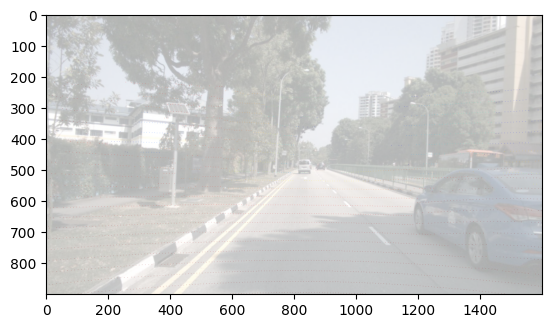

In [52]:
plt.imshow(depth_on_img)
# h, w
valid_depth_value.shape, valid_depth_pixel.sum()

In [124]:
# extrinsic存在误差。对于 world 下 cam 坐标，需要从 colmap 获取优化后结果。
from lib.utils.colmap_utils import read_extrinsics_binary

cam_extrinsics = read_extrinsics_binary(os.path.join(colmap_basedir, "triangulated/sparse/model/images.bin"))


cam_extrinsics[1]


Image(id=1, qvec=array([ 7.26145600e-01,  6.87503447e-01,  6.78449160e-04, -7.14970640e-03]), tvec=array([-0.00815136, -0.35211534, -0.82456788]), camera_id=0, name='cam_0/000.png', xys=array([[ 198.8427887 ,    3.37108421],
       [ 198.8427887 ,    3.37108421],
       [ 204.4161377 ,    7.37079144],
       ...,
       [1263.88134766,  151.80712891],
       [1592.09558105,  229.20272827],
       [1072.4432373 ,  649.28442383]]), point3D_ids=array([  -1,   -1,   -1, ..., 2808,   -1,   -1]))

In [92]:
from scipy.spatial.transform import Rotation as R

image_id = 150

rquat = np.array(cam_extrinsics[image_id].qvec)
rquat[3], rquat[0], rquat[1], rquat[2] = rquat[0], rquat[1], rquat[2], rquat[3]

transform_inv = np.eye(4)
transform_inv[:3,:3] = R.from_quat(rquat).as_matrix()
transform_inv[:3, 3] = cam_extrinsics[image_id].tvec
# transform_inv
transform = np.linalg.inv(transform_inv)
cam_extrinsics[image_id].name

'cam_3/014.png'

In [175]:
lidar_filepaths[0].replace("lidar", "lidar_depth").replace(".bin", "_%d.png"%cam_id)


'/home/zyk/Projects/_DL/_Reconstruction/drivestudio/data/nuscenes/processed_10Hz/mini/000/lidar_depth/000_0.png'

In [36]:
lidar_filepaths[0].replace("lidar", "lidar_depth").replace(".bin", "_%d.npy"%cam_id)

'/home/zyk/Projects/_DL/_Reconstruction/drivestudio/data/nuscenes/processed_10Hz/mini/000/lidar_depth/000_5.npy'

In [55]:
data = np.load("/home/zyk/Projects/_DL/_Reconstruction/street_gaussians_new_start/data/waymo/training/021/lidar_depth/000000_0.npy", allow_pickle=True).item()

# plt.imshow(data['mask'])
data['mask'].shape, data["value"]
# data['mask'].sum(), data["value"].shape

((1280, 1920),
 array([13.49685177, 12.28283552, 12.20713293, ...,  6.99609328,
         6.96897988,  6.94186203]))

In [93]:
depth = (np.ones((h, w)) * np.finfo(np.float32).max).reshape(-1)
u, v = points_coord[:, 0], points_coord[:, 1]
indices = v * w + u
np.minimum.at(depth, indices, points_depth[valid_mask])
depth[depth >= np.finfo(np.float32).max - 1e-5] = 0
valid_depth_pixel = (depth != 0)
valid_depth_value = depth[valid_depth_pixel]
valid_depth_pixel = valid_depth_pixel.reshape(h, w).astype(np.bool_)

depth_file = dict()
depth_file['mask'] = valid_depth_pixel
depth_file['value'] = valid_depth_value
np.save(depth_path, depth_file)


NameError: name 'points_coord' is not defined

In [94]:
# tmp = np.array([1, 0.7136892544167476, 0.7004512300974711, 0.0037091146913228157, 0.0014017322187676287, 0.014369483884301206, -0.33860960762719355, -0.3195679942225384, 0])

tmp = np.array([1176, 0.010276434709076382, 0.042760173717814015, 0.7184385874933621, -0.6941987888449785, -8.11454610731147, 3.431406774099522, 235.66619109452677])

rquat = np.array(tmp[1:5])
rquat[3], rquat[0], rquat[1], rquat[2] = rquat[0], rquat[1], rquat[2], rquat[3]
rquat

array([ 0.04276017,  0.71843859, -0.69419879,  0.01027643])

In [95]:
transform_inv = np.eye(4)
transform_inv[:3,:3] = R.from_quat(rquat).as_matrix()
transform_inv[:3, 3] = tmp[5:8]
transform_inv

array([[-9.96131925e-01,  7.57088947e-02, -4.46021471e-02,
        -8.11454611e+00],
       [ 4.71733406e-02,  3.25192182e-02, -9.98357239e-01,
         3.43140677e+00],
       [-7.41340961e-02, -9.96599550e-01, -3.59648729e-02,
         2.35666191e+02],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00]])

In [ ]:
np.linalg.inv(transform_inv)

In [96]:

import open3d as o3d
raw_pt = o3d.geometry.PointCloud()

raw_pt.points = o3d.utility.Vector3dVector(local_lidar_points[:,:3])

FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=10, origin=[0, 0, 0])

o3d.visualization.draw_geometries([raw_pt])



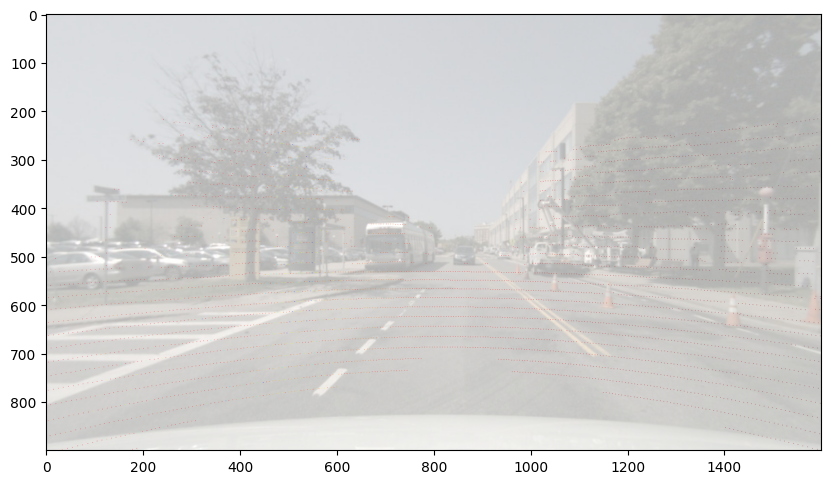

In [97]:
from lib.utils.img_utils import visualize_depth_numpy
# h, w = image.shape[:2]
# depth = (np.ones((h, w)) * np.finfo(np.float32).max).reshape(-1)
# u, v = _cam_points[:, 0], _cam_points[:, 1]
# indices = v * w + u
# np.minimum.at(depth, indices, valid_depth_value)
# depth[depth >= np.finfo(np.float32).max - 1e-5] = 0

# depth = depth.reshape(h, w).astype(np.float32)
# depth_vis, _ = visualize_depth_numpy(depth)
# depth_on_img = np.ones_like(image[..., [2, 1, 0]])*255
# depth_on_img[depth > 0] = depth_vis[depth > 0]
# # cv2.imwrite(depth_vis_path, depth_on_img)  
# plt.figure(figsize=(10,10))
# plt.imshow(depth_on_img)
# (depth>0).sum()

# depth.shape
image2 = 255 - (255 - np.array(image)) // 3
# image2 = np.ones_like(image) * 255
depth_vis = visualize_depth_numpy(valid_depth_value)[0][:,0,:]

for dx, dy in [[0,0]]:
    image2[_cam_points[:, 1] + dx, _cam_points[:, 0] + dy] = depth_vis
#     image2[_cam_points[:, 1] + dx, _cam_points[:, 0] + dy, 0] = visualize_depth_numpy(valid_depth_value)
#     image2[_cam_points[:, 1] + dx, _cam_points[:, 0] + dy, 1] = 0
#     image2[_cam_points[:, 1] + dx, _cam_points[:, 0] + dy, 2] = 0

plt.figure(figsize=(10,10))
plt.imshow(image2)

In [125]:
# 读取 p3d 和 p2d 看看
# points = []
# colors = []

# for cam_id in cams:
#     image = plt.imread(os.path.join(data_path, "images", f"{t:03d}_{cam_id}.jpg"))

#     v = (camera_projection[:,0] != -1)
#     w = camera_projection[v, 1]
#     h = camera_projection[v, 2]
    
#     points.append(local_lidar_points[v])
#     colors.append(image[h, w])
    
points = np.concatenate(points)    
colors = np.concatenate(colors)    



In [61]:
import open3d as o3d
world_origin = o3d.geometry.PointCloud()
world_origin.points = o3d.utility.Vector3dVector(points)
world_origin.colors = o3d.utility.Vector3dVector(colors / 255)

FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=1, origin=[0, 0, 0])

o3d.visualization.draw_geometries([world_origin, FOR1])


In [ ]:
# np.savez_compressed(os.path.join(data_path, 'pointcloud.npz'), 
#                     pointcloud=pts_3d_all, 
#                     camera_projection=pts_2d_all)



In [ ]:
# # if build_pointcloud:
# datadir='/home/zyk/Projects/_DL/_Reconstruction/street_gaussians/data/waymo/training/021'

# print('initialize from lidar pointcloud')
# pointcloud_path = os.path.join(datadir, 'pointcloud.npz')
# pts3d_dict = np.load(pointcloud_path, allow_pickle=True)['pointcloud'].item()
# pts2d_dict = np.load(pointcloud_path, allow_pickle=True)['camera_projection'].item()

In [ ]:
# import open3d as o3d
# world_origin = o3d.geometry.PointCloud()
# world_origin.points = o3d.utility.Vector3dVector(pts3d_dict[0])
# world_origin.colors = o3d.utility.Vector3dVector(points_color/256)

# FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=10, origin=[0, 0, 0])

# o3d.visualization.draw_geometries([world_origin, FOR1])


In [126]:
from lib.utils.general_utils import matrix_to_quaternion, quaternion_to_matrix_numpy


waymo_track2label = {"vehicle": 0, "Vehicle": 0,
                     "pedestrian": 1, "Pedestrian": 1, 
                     "cyclist": 2, 
                     "sign": 3, 
                     "misc": -1}
image_heights = [900, 900, 900, 900, 900, 900]
image_widths = [1600, 1600, 1600, 1600, 1600, 1600]


image_filename_to_cam = lambda x: int(x.split('.')[0][-1])
# image_filename_to_frame = lambda x: int(x.split('.')[0][:6])
image_filename_to_frame = lambda x: int(x.split('.')[0][:3])


def load_camera_info_ds(datadir):
    lidar_pose_dir = os.path.join(datadir, 'lidar_pose')
    extrinsics_dir = os.path.join(datadir, 'extrinsics')
    intrinsics_dir = os.path.join(datadir, 'intrinsics')
    
    intrinsics = [] # 5cam
    extrinsics = [] # 5cam
    for i in range(6):
        intrinsic = np.loadtxt(os.path.join(intrinsics_dir,  f"{i}.txt"))
        fx, fy, cx, cy = intrinsic[0], intrinsic[1], intrinsic[2], intrinsic[3]
        intrinsic = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]])
        intrinsics.append(intrinsic)
        
        lidar_to_world_start = np.loadtxt(os.path.join(lidar_pose_dir, "000.txt"))
        camera_front_start = np.loadtxt(
            os.path.join(extrinsics_dir, f"000_{i:01d}.txt")
        )
        ext = np.linalg.inv(lidar_to_world_start) @  camera_front_start
        extrinsics.append(ext)

    ## Nuscenes
    ego_cam_poses = [[] for i in range(6)]
    extrinsics_paths = sorted(os.listdir(extrinsics_dir))
    for ext_path in extrinsics_paths:
        cam2world = np.loadtxt(os.path.join(extrinsics_dir, ext_path))
        cam_id = int(ext_path.split(".")[0].split("_")[-1])
        cam2world = np.linalg.inv(lidar_to_world_start) @ cam2world
        ego_cam_poses[cam_id].append(cam2world)

    ego_frame_poses = []
    ego_pose_paths = sorted(os.listdir(lidar_pose_dir))
    for ego_pose_path in ego_pose_paths:
        lidar_to_world = np.loadtxt(os.path.join(lidar_pose_dir, ego_pose_path))
        lidar_to_world = np.linalg.inv(lidar_to_world_start) @ lidar_to_world
        ego_frame_poses.append(lidar_to_world)
    
    # center ego pose
    ego_frame_poses = np.array(ego_frame_poses)
    center_point = np.mean(ego_frame_poses[:, :3, 3], axis=0)
    # ego_frame_poses[:, :3, 3] -= center_point # [num_frames, 4, 4]
    
#     ego_cam_poses = [np.array(ego_cam_poses[i]) for i in range(6)]
    ego_cam_poses = np.array(ego_cam_poses)
    # ego_cam_poses[:, :, :3, 3] -= center_point # [5, num_frames, 4, 4]
    return intrinsics, extrinsics, ego_frame_poses, ego_cam_poses
            # 内参，首帧各cam对lidar相对位姿，世界坐标系lidar位姿，世界坐标系各cam位姿  

def make_obj_pose_ds(ego_pose_world, obj_pose_world):
    # obj_pose_world = np.matmul(ego_pose_world, obj_pose_vehicle)
    obj_pose_vehicle = np.matmul(np.linalg.inv(ego_pose_world), obj_pose_world)

    obj_rotation_vehicle = torch.from_numpy(obj_pose_vehicle[:3, :3]).float().unsqueeze(0)
    obj_quaternion_vehicle = matrix_to_quaternion(obj_rotation_vehicle).squeeze(0).numpy()
    obj_quaternion_vehicle = obj_quaternion_vehicle / np.linalg.norm(obj_quaternion_vehicle)
    obj_position_vehicle = obj_pose_vehicle[:3, 3]
    obj_pose_vehicle = np.concatenate([obj_position_vehicle, obj_quaternion_vehicle])

    obj_rotation_world = torch.from_numpy(obj_pose_world[:3, :3]).float().unsqueeze(0)
    obj_quaternion_world = matrix_to_quaternion(obj_rotation_world).squeeze(0).numpy()
    obj_quaternion_world = obj_quaternion_world / np.linalg.norm(obj_quaternion_world)
    obj_position_world = obj_pose_world[:3, 3]
    obj_pose_world = np.concatenate([obj_position_world, obj_quaternion_world])

    return obj_pose_vehicle, obj_pose_world    

In [ ]:
data_path

In [127]:
# data_path = '/home/zyk/Projects/_DL/_Reconstruction/drivestudio/data/nuscenes/processed_10Hz/mini/001'

datadir = data_path
# cameras=[0, 1, 2, 3, 4, 5]
# cameras=[0, 1, 2, 3, 4]

image_dir = os.path.join(datadir, 'images')
image_filenames_all = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))
num_cameras = len(cameras)
num_frames_all = len(image_filenames_all) // num_cameras

selected_frames = [0, num_frames_all]


In [128]:
# generate_dataparser_outputs 前半部分 到get_obj_pose_tracking之前

# def generate_dataparser_outputs(
#         datadir, 
#         selected_frames=None, 
#         build_pointcloud=True, 
#         cameras=[0, 1, 2, 3, 4]
#     ):

# image_dir = os.path.join(datadir, 'images')
# image_filenames_all = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))
# num_cameras = len(cameras)
# num_frames_all = len(image_filenames_all) // num_cameras

if selected_frames is None:
    start_frame = 0
    end_frame = num_frames_all - 1
    selected_frames = [start_frame, end_frame]
else:
    start_frame, end_frame = selected_frames[0], selected_frames[1]
num_frames = end_frame - start_frame + 1

# load calibration and ego pose
intrinsics, extrinsics, ego_frame_poses, ego_cam_poses = load_camera_info_ds(datadir)    
# intrinsics 内参，
# extrinsics 首帧各 cam 对 lidar 相对位姿，
# ego_frame_poses 世界坐标系 lidar 位姿，
# ego_cam_poses 世界坐标系各cam位姿

# intrinsics, extrinsics, ego_frame_poses = load_camera_info_ds(datadir)    

# load camera, frame, path
frames = []
frames_idx = []
cams = []
image_filenames = []

ixts = []
exts = []
poses = []
c2ws = []

frames_timestamps = []
cams_timestamps = []

split_test = -1
split_train = -1
# train_frames, test_frames = get_val_frames(
#     num_frames, 
#     test_every=split_test if split_test > 0 else None,
#     train_every=split_train if split_train > 0 else None,
# )

# timestamp_path = os.path.join(datadir, 'timestamps.json')
# with open(timestamp_path, 'r') as f:
#     timestamps = json.load(f)

for frame in range(start_frame, end_frame+1):
#     frames_timestamps.append(timestamps['FRAME'][f'{frame:06d}'])
    frames_timestamps.append(frame)

for image_filename in image_filenames_all:
    image_basename = os.path.basename(image_filename)
    frame = image_filename_to_frame(image_basename)
    cam = image_filename_to_cam(image_basename)
    if frame >= start_frame and frame <= end_frame and cam in cameras:
        ixt = intrinsics[cam]
        ext = extrinsics[cam]
        # pose = ego_cam_poses[cam, frame]
        pose = ego_frame_poses[frame]
        # c2w = pose @ ext
        c2w = ego_cam_poses[cam, frame]

        frames.append(frame)
        frames_idx.append(frame - start_frame)
        cams.append(cam)
        image_filenames.append(image_filename)

        ixts.append(ixt)
        exts.append(ext)
        poses.append(pose)
        c2ws.append(c2w)

        # camera_name = _label2camera[cam]
        # timestamp = timestamps[camera_name][f'{frame:06d}']
        timestamp = frame
        cams_timestamps.append(timestamp)

exts = np.stack(exts, axis=0)
ixts = np.stack(ixts, axis=0)
poses = np.stack(poses, axis=0)
c2ws = np.stack(c2ws, axis=0)

# timestamp_offset = min(cams_timestamps + frames_timestamps)
timestamp_offset = 0
cams_timestamps = np.array(cams_timestamps) - timestamp_offset
frames_timestamps = np.array(frames_timestamps) - timestamp_offset
min_timestamp, max_timestamp = min(cams_timestamps.min(), frames_timestamps.min()), max(cams_timestamps.max(), frames_timestamps.max())


In [ ]:
image_filenames

In [129]:
# 修改 DriveStudio数据对应的 get_obj_pose_tracking
# get_obj_pose_tracking 前半部分



image_dir = os.path.join(datadir, 'images')
image_filenames_all = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))

num_cameras = len(cameras)
num_frames_all = len(image_filenames_all) // num_cameras
start_frame, end_frame = selected_frames[0], selected_frames[1]
num_frames = end_frame - start_frame + 1

intrinsics, extrinsics, ego_frame_poses, ego_cam_poses = load_camera_info_ds(datadir)    


ego_poses = ego_frame_poses
# def get_obj_pose_tracking(datadir, selected_frames, ego_poses, cameras=[0, 1, 2, 3, 4]):


tracklets_ls = []    
objects_info = {}

frame_instances_path = os.path.join(datadir, 'instances/frame_instances.json')
instances_info_path = os.path.join(datadir, 'instances/instances_info.json')

with open(frame_instances_path, "r") as f:
    frame_instances = json.load(f)

with open(instances_info_path, "r") as f:
    instances_info = json.load(f)


start_frame, end_frame = selected_frames[0], selected_frames[1]

image_dir = os.path.join(datadir, 'images')
n_images = len(os.listdir(image_dir))
n_frames = n_images // num_cameras
n_obj_in_frame = np.zeros(n_frames)

for track_id_str in instances_info.keys():
    track_id = int(track_id_str)
    track_instance = instances_info[track_id_str]

    object_class = track_instance["class_name"]
    if "vehicle" in object_class:
        object_class = "vehicle"
    elif "pedestrian" in object_class:
        object_class = "pedestrian"

    if track_id not in objects_info.keys():
        objects_info[track_id] = dict()
        objects_info[track_id]['track_id'] = track_id
        objects_info[track_id]['class'] = object_class 
        objects_info[track_id]['class_label'] = waymo_track2label[object_class]
        objects_info[track_id]['height'] = track_instance["frame_annotations"]["box_size"][0][2]
        objects_info[track_id]['width'] = track_instance["frame_annotations"]["box_size"][0][1]
        objects_info[track_id]['length'] = track_instance["frame_annotations"]["box_size"][0][0]

    else:
        objects_info[track_id]['height'] = max(objects_info[track_id]['height'], track_instance["frame_annotations"]["box_size"][0][2])
        objects_info[track_id]['width'] = max(objects_info[track_id]['width'], track_instance["frame_annotations"]["box_size"][0][1])
        objects_info[track_id]['length'] = max(objects_info[track_id]['length'], track_instance["frame_annotations"]["box_size"][0][0])

tracklets_array = np.array(tracklets_ls)
max_obj_per_frame = int(n_obj_in_frame[start_frame:end_frame + 1].max())
num_frames = end_frame - start_frame + 1
visible_objects_ids = np.ones([num_frames, max_obj_per_frame]) * -1.0
visible_objects_pose_vehicle = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0
visible_objects_pose_world = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0

for frame_id in frame_instances.keys():
    n_obj_in_frame[int(frame_id)] = len(frame_instances[frame_id])

num_frames = end_frame - start_frame + 1
max_obj_per_frame = int(n_obj_in_frame[start_frame:end_frame + 1].max())



visible_objects_ids = np.ones([num_frames, max_obj_per_frame]) * -1.0
visible_objects_pose_vehicle = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0
visible_objects_pose_world = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0

cnt = 0
for k, v in instances_info.items():
    track_id = int(k)

    for frame_id, obj_to_world, box_size in zip(v["frame_annotations"]["frame_idx"], v["frame_annotations"]["obj_to_world"], v["frame_annotations"]["box_size"]):

# ################# 此处 DS所用ID track_id，与 STG所用ID tracklet_camera_vis是不一致的。
#         cameras_vis_list = tracklet_camera_vis[str(track_id)][str(frame_id)]
#         join_cameras_list = list(set(cameras) & set(cameras_vis_list))
#         if len(join_cameras_list) == 0:
#             continue
# ####################
        if start_frame <= frame_id <= end_frame:            

            cnt += 1

            frame_idx = frame_id - start_frame

            # ego_to_world_start = np.loadtxt(os.path.join(datadir, "ego_pose", f"{frame_idx:03d}.txt"))

            obj_to_world = np.array(obj_to_world).reshape(4, 4)
            # obj_pose_vehicle_mat = np.linalg.inv(ego_to_world_start) @ obj_to_world
            obj_pose_world_mat = obj_to_world

            ego_pose_world = ego_poses[frame_id]
            obj_pose_vehicle, obj_pose_world = make_obj_pose_ds(ego_pose_world, obj_pose_world_mat)

            obj_column = np.argwhere(visible_objects_ids[frame_idx, :] < 0).min()

            visible_objects_ids[frame_idx, obj_column] = track_id
            visible_objects_pose_vehicle[frame_idx, obj_column] = obj_pose_vehicle
            visible_objects_pose_world[frame_idx, obj_column] = obj_pose_world

# Remove static objects
print("Removing static objects")
for key in objects_info.copy().keys():
    all_obj_idx = np.where(visible_objects_ids == key)
    if len(all_obj_idx[0]) > 0:
        obj_world_postions = visible_objects_pose_world[all_obj_idx][:, :3]
        distance = np.linalg.norm(obj_world_postions[0] - obj_world_postions[-1])
        dynamic = np.any(np.std(obj_world_postions, axis=0) > 0.5) or distance > 2
        if not dynamic:
            visible_objects_ids[all_obj_idx] = -1.
            visible_objects_pose_vehicle[all_obj_idx] = -1.
            visible_objects_pose_world[all_obj_idx] = -1.
            objects_info.pop(key)
    else:
        objects_info.pop(key)

# Clip max_num_obj
mask = visible_objects_ids >= 0
max_obj_per_frame_new = np.sum(mask, axis=1).max()
print("Max obj per frame:", max_obj_per_frame_new)

if max_obj_per_frame_new == 0:
    print("No moving obj in current sequence, make dummy visible objects")
    visible_objects_ids = np.ones([num_frames, 1]) * -1.0
    visible_objects_pose_world = np.ones([num_frames, 1, 7]) * -1.0
    visible_objects_pose_vehicle = np.ones([num_frames, 1, 7]) * -1.0    
elif max_obj_per_frame_new < max_obj_per_frame:
    visible_objects_ids_new = np.ones([num_frames, max_obj_per_frame_new]) * -1.0
    visible_objects_pose_vehicle_new = np.ones([num_frames, max_obj_per_frame_new, 7]) * -1.0
    visible_objects_pose_world_new = np.ones([num_frames, max_obj_per_frame_new, 7]) * -1.0
    for frame_idx in range(num_frames):
        for y in range(max_obj_per_frame):
            obj_id = visible_objects_ids[frame_idx, y]
            if obj_id >= 0:
                obj_column = np.argwhere(visible_objects_ids_new[frame_idx, :] < 0).min()
                visible_objects_ids_new[frame_idx, obj_column] = obj_id
                visible_objects_pose_vehicle_new[frame_idx, obj_column] = visible_objects_pose_vehicle[frame_idx, y]
                visible_objects_pose_world_new[frame_idx, obj_column] = visible_objects_pose_world[frame_idx, y]

    visible_objects_ids = visible_objects_ids_new
    visible_objects_pose_vehicle = visible_objects_pose_vehicle_new
    visible_objects_pose_world = visible_objects_pose_world_new

box_scale =1.5
print('box scale: ', box_scale)

frames = list(range(start_frame, end_frame + 1))
frames = np.array(frames).astype(np.int32)

# postprocess object_info   
for key in objects_info.keys():
    obj = objects_info[key]
    if obj['class'] == 'Pedestrian':
        obj['deformable'] = True
    else:
        obj['deformable'] = False

    obj['width'] = obj['width'] * box_scale
    obj['length'] = obj['length'] * box_scale

    obj_frame_idx = np.argwhere(visible_objects_ids == key)[:, 0]
    obj_frame_idx = obj_frame_idx.astype(np.int32)
    obj_frames = frames[obj_frame_idx]
    obj['start_frame'] = np.min(obj_frames)
    obj['end_frame'] = np.max(obj_frames)

    objects_info[key] = obj

# [num_frames, max_obj, track_id, x, y, z, qw, qx, qy, qz]
objects_tracklets_world = np.concatenate(
    [visible_objects_ids[..., None], visible_objects_pose_world], axis=-1
)

objects_tracklets_vehicle = np.concatenate(
    [visible_objects_ids[..., None], visible_objects_pose_vehicle], axis=-1
)


# return objects_tracklets_world, objects_tracklets_vehicle, objects_info
object_tracklets_vehicle = objects_tracklets_vehicle
object_info = objects_info

Removing static objects
Max obj per frame: 8
box scale:  1.5


In [ ]:
v["frame_annotations"]["frame_idx"]

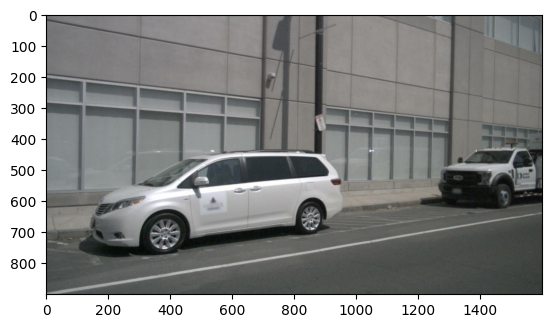

In [130]:
# 重新拼接 坐标转换部分
# def get_obj_pose_tracking(datadir, selected_frames, ego_poses, cameras=[0, 1, 2, 3, 4]):

# for track_id_str in instances_info.keys():

#  1310: 查1号车

track_id_str = '0'
track_id = int(track_id_str)
track_instance = instances_info[track_id_str]

object_class = track_instance["class_name"]
if "vehicle" in object_class:
    object_class = "vehicle"
elif "pedestrian" in object_class:
    object_class = "pedestrian"

if track_id not in objects_info.keys():
    objects_info[track_id] = dict()
    objects_info[track_id]['track_id'] = track_id
    objects_info[track_id]['class'] = object_class 
    objects_info[track_id]['class_label'] = waymo_track2label[object_class]
    objects_info[track_id]['height'] = track_instance["frame_annotations"]["box_size"][0][2]
    objects_info[track_id]['width'] = track_instance["frame_annotations"]["box_size"][0][1]
    objects_info[track_id]['length'] = track_instance["frame_annotations"]["box_size"][0][0]

else:
    objects_info[track_id]['height'] = max(objects_info[track_id]['height'], track_instance["frame_annotations"]["box_size"][0][2])
    objects_info[track_id]['width'] = max(objects_info[track_id]['width'], track_instance["frame_annotations"]["box_size"][0][1])
    objects_info[track_id]['length'] = max(objects_info[track_id]['length'], track_instance["frame_annotations"]["box_size"][0][0])

v = instances_info[track_id_str]
# for frame_id, obj_to_world, box_size in zip(v["frame_annotations"]["frame_idx"], v["frame_annotations"]["obj_to_world"], v["frame_annotations"]["box_size"]):

_t = 10
frame_id = v["frame_annotations"]["frame_idx"][_t]
obj_to_world = v["frame_annotations"]["obj_to_world"][_t]
box_size = v["frame_annotations"]["box_size"][_t]

assert start_frame <= frame_id <= end_frame

    
frame_idx = frame_id - start_frame

# ego_to_world_start = np.loadtxt(os.path.join(datadir, "ego_pose", f"{frame_idx:03d}.txt"))

obj_to_world = np.array(obj_to_world).reshape(4, 4)
# obj_pose_vehicle_mat = np.linalg.inv(ego_to_world_start) @ obj_to_world
obj_pose_world_mat = obj_to_world

ego_pose_world = ego_frame_poses[frame_id]
obj_pose_vehicle, obj_pose_world = make_obj_pose_ds(ego_pose_world, obj_pose_world_mat)

image_idx = frame_idx * num_cameras + 5
plt.imshow(plt.imread(image_filenames_all[image_idx]))


In [131]:
# for i, frame in tqdm(enumerate(range(start_frame, end_frame+1))):
# 固定frame后第一部分

normals_world_all = []
N_VIEWS = (end_frame-start_frame+1)*num_cameras


# i = frame_id // num_cameras


idxs = list(range(frame_id * num_cameras, (frame_id+1) * num_cameras))
cams_frame = [cams[idx] for idx in idxs]
image_filenames_frame = [image_filenames_all[idx] for idx in idxs]

raw_3d = pts_3d_all[frame_id]
raw_2d = pts_2d_all[frame_id]

# use the first projection camera
points_camera_all = raw_2d[..., 0] 

# each point should be observed by at least one camera in camera lists
mask = np.array([c in cameras for c in points_camera_all]).astype(np.bool_)

points_xyz_vehicle = raw_3d[mask]
ego_pose = ego_frame_poses[frame_id]

points_xyz_vehicle = np.concatenate([points_xyz_vehicle, np.ones([points_xyz_vehicle.shape[0], 1])], axis=1)
points_xyz_world = points_xyz_vehicle @ ego_pose.T

points_rgb = np.ones_like(points_xyz_vehicle[:, :3])
points_normal = np.ones_like(points_xyz_vehicle[:, :3])
# points_trackview = np.ones_like(points_xyz_vehicle[:, :1]).astype(np.int16) * -1
points_visibility = np.zeros([points_xyz_vehicle.shape[0], N_VIEWS]).astype(np.bool_) 


# my_vis(points_xyz_vehicle, points_rgb*0, points_normal, coord_size=15)

In [105]:
import open3d as o3d
raw_pt = o3d.geometry.PointCloud()

raw_pt.points = o3d.utility.Vector3dVector(raw_3d[(np.linalg.norm(raw_3d, axis=1) > 2),:3])

FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=10, origin=[0, 0, 0])

o3d.visualization.draw_geometries([raw_pt, FOR1])


In [ ]:
(np.linalg.norm(raw_3d, axis=1) > 1).sum()

In [ ]:
points_camera_all.shape

In [ ]:
idx // num_cameras

In [133]:
# 固定frame后第二部分

# 多帧。看坐标转换是否正确

for cam, image_filename, idx in zip(cams_frame, image_filenames_frame, idxs):
    frame = idx // num_cameras
    # mask_cam = (points_camera == cam)
    image = cv2.imread(image_filename)[..., [2, 1, 0]] / 255.
    normal_filename = image_filename.replace("images", "normal_img").replace("jpg", "png")
    normal_dsine = cv2.imread(normal_filename) / 255 * 2 - 1
    # DSINE 估计结果为左手系
    normals_transformed = np.zeros_like(normal_dsine)
    normals_transformed[..., 0] = -normal_dsine[..., 2]  # X_new = -X_old
    normals_transformed[..., 1] = -normal_dsine[..., 1]   # Y_new = Z_old
    normals_transformed[..., 2] = -normal_dsine[..., 0]

    ext = extrinsics[cam]
    # pose = ego_cam_poses[cam, frame]
    pose = ego_frame_poses[frame]
    # c2w = pose @ ext
    ixt = ixts[idx]
    c2w = c2ws[idx]
    # normals_world = normals_transformed @ ego_pose[:3, :3].T # (H, W, 3) * (3, 3)
    normals_world = normals_transformed @ c2w[:3,:3].T # @ np.linalg.inv(ext)[:3, :3] 
    # points_xyz_cam = points_xyz @ w2c.T
    normals_world_all.append(normals_world)

    view_pos_world = np.concatenate([points_xyz_world[:,:3], np.ones_like(points_xyz_world[:,:1])], axis=-1)
    view_pos_cam = view_pos_world @ np.linalg.inv(c2w).T

    tmp = view_pos_cam[:,:3] @ ixt.T
    us = (tmp[:,0] / tmp[:,2]).astype(np.int16)
    vs = (tmp[:,1] / tmp[:,2]).astype(np.int16)

    mask = np.logical_and(us >= 0, us < image.shape[1])
    mask = np.logical_and(mask, vs >= 0)
    mask = np.logical_and(mask, vs < image.shape[0])
    mask = np.logical_and(mask, tmp[:, 2] > 0)

    # image2 = np.array(image)
    # image2[vs[mask], us[mask], 0] = 1
    # image2[vs[mask], us[mask], 1] = 0
    # image2[vs[mask], us[mask], 2] = 0
    # plt.imshow(image2)
    mask_projw = us[mask]
    mask_projh = vs[mask]


    # mask_projw = points_projw[mask_cam]
    # mask_projh = points_projh[mask_cam]

    # image2 = np.array(image)
    # image2[mask_projh, mask_projw] = 0
    # image2[mask_projh, mask_projw, 0] = 1
    # plt.imshow(image2)

    # 每个lidar point对绑定图像取色
    mask_rgb = image[mask_projh, mask_projw]
    mask_normal = normals_world[mask_projh, mask_projw]

    # points_rgb[mask_cam] = mask_rgb
    # points_normal[mask_cam] = mask_normal
    points_rgb[mask] = mask_rgb
    points_normal[mask] = mask_normal
    # points_trackview[mask_cam] = idx
    points_visibility[mask, idx] = True

## Normal Prior Visualization
# my_vis(points_xyz_world, points_rgb, points_normal)

# filer points in tracking bbox
points_xyz_obj_mask = np.zeros(points_xyz_vehicle.shape[0], dtype=np.bool_)


In [ ]:
points_xyz_obj_mask.sum()

In [132]:
# 初始化
points_xyz_dict = dict()
points_rgb_dict = dict()
points_normal_dict = dict()
points_view_dict = dict()

points_xyz_dict['bkgd'] = []
points_rgb_dict['bkgd'] = []
points_normal_dict['bkgd'] = []
points_view_dict['bkgd'] = []

for track_id in object_info.keys():
    points_xyz_dict[f'obj_{track_id:03d}'] = []
    points_rgb_dict[f'obj_{track_id:03d}'] = []
    points_normal_dict[f'obj_{track_id:03d}'] = []
    points_view_dict[f'obj_{track_id:03d}'] = []

In [134]:
# for tracklet in object_tracklets_vehicle[i]:
#     track_id = int(tracklet[0])
#     print(track_id)
    
#     if track_id >= 0:


######## 以下本应在converter部分，过后删除： 
# track_id = 2

v = instances_info[str(track_id)]

# _t = 20
frame_id = v["frame_annotations"]["frame_idx"][_t]
obj_to_world = v["frame_annotations"]["obj_to_world"][_t]
box_size = v["frame_annotations"]["box_size"][_t]

# for frame_id, obj_to_world, box_size in zip(v["frame_annotations"]["frame_idx"], v["frame_annotations"]["obj_to_world"], v["frame_annotations"]["box_size"]):
#     if start_frame <= frame_id <= end_frame:            

frame_idx = frame_id - start_frame


obj_pose_world_mat = np.array(obj_to_world).reshape(4, 4)

ego_pose_world = ego_poses[frame_id]
obj_pose_vehicle, obj_pose_world = make_obj_pose_ds(ego_pose_world, obj_pose_world_mat)


            
#######################################################            

if False:
    obj_pose_vehicle_mat = np.matmul(np.linalg.inv(ego_pose_world), obj_pose_world_mat)
else:
#     tracklet = object_tracklets_vehicle[frame_idx][track_id]
    tracklet = obj_pose_vehicle

    obj_pose_vehicle_mat = np.eye(4)               
    obj_pose_vehicle_mat[:3, :3] = quaternion_to_matrix_numpy(tracklet[3:7])
    obj_pose_vehicle_mat[:3, 3] = tracklet[0:3]

vehicle2local = np.linalg.inv(obj_pose_vehicle_mat)

# 注：world与vehicle关系: points_xyz_world = points_xyz_vehicle @ ego_pose.T
points_xyz_obj = points_xyz_vehicle @ vehicle2local.T
points_xyz_obj = points_xyz_obj[..., :3]
points_normal_obj = points_normal @ np.linalg.inv(ego_pose[:3,:3]).T @ vehicle2local[:3,:3].T
# my_vis(points_xyz_obj, points_rgb, points_normal_obj)

length = object_info[track_id]['length']
width = object_info[track_id]['width']
height = object_info[track_id]['height']
bbox = [[-length/2, -width/2, -height/2], [length/2, width/2, height/2]]
obj_corners_3d_local = bbox_to_corner3d(bbox)

points_xyz_inbbox = inbbox_points(points_xyz_obj, obj_corners_3d_local)

points_xyz_obj_mask = np.logical_or(points_xyz_obj_mask, points_xyz_inbbox)
points_xyz_dict[f'obj_{track_id:03d}'].append(points_xyz_obj[points_xyz_inbbox])
points_rgb_dict[f'obj_{track_id:03d}'].append(points_rgb[points_xyz_inbbox])
points_normal_dict[f'obj_{track_id:03d}'].append(points_normal_obj[points_xyz_inbbox])
points_view_dict[f'obj_{track_id:03d}'].append(points_visibility[points_xyz_inbbox])
# my_vis(points_xyz_obj[points_xyz_inbbox], points_rgb[points_xyz_inbbox], points_normal_obj[points_xyz_inbbox])

#         if points_xyz_inbbox.sum() > 0:
#             break
#     if points_xyz_inbbox.sum() > 0:
#             break
points_xyz_inbbox.sum()

0

In [109]:
import open3d as o3d
obj_corner = o3d.geometry.PointCloud()
obj_corner.points = o3d.utility.Vector3dVector(obj_corners_3d_local[:,:3])


world_origin = o3d.geometry.PointCloud()
world_origin.points = o3d.utility.Vector3dVector(points_xyz_obj[:,:3])
world_origin.colors = o3d.utility.Vector3dVector(points_rgb)

FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=10, origin=[0, 0, 0])

o3d.visualization.draw_geometries([obj_corner, world_origin, FOR1])


In [38]:
import open3d as o3d
obj = o3d.geometry.PointCloud()
obj.points = o3d.utility.Vector3dVector(points_xyz_obj[points_xyz_inbbox])
obj.colors = o3d.utility.Vector3dVector(points_rgb[points_xyz_inbbox])

FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=10, origin=[0, 0, 0])

o3d.visualization.draw_geometries([obj, world_origin, FOR1])


[Open3D WARNING] The number of points is 0 when creating axis-aligned bounding box.


以下为sam相关mask制作部分

In [135]:
# Normal prior 可视化
def my_vis(points_xyz_world, points_rgb, points_normal=None, coord_size=15):
    normal_lines = []
    line_colors = []
    # tmp = points_xyz_vehicle[mask_cam] @ ego_pose.T
    tmp = points_xyz_world[:,:3]
    
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points_xyz_world[:,:3])                
    pcd.colors = o3d.utility.Vector3dVector(points_rgb)
    
    FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=coord_size, origin=[0, 0, 0])

    if points_normal is None:
        o3d.visualization.draw_geometries([pcd, FOR1])
        return
    
    
    for j in range(tmp.shape[0]):
        p1 = tmp[j]
        p2 = tmp[j] + points_normal[j] * 0.2  # 放大法向量
        normal_lines.append([p1, p2])
        line_colors.append([1, 0, 0])  # 颜色（红色表示法向量）

    line_set = o3d.geometry.LineSet()
    line_set.points = o3d.utility.Vector3dVector(np.vstack(normal_lines))
    line_set.lines = o3d.utility.Vector2iVector(np.arange(len(normal_lines) * 2).reshape(-1, 2))
    line_set.colors = o3d.utility.Vector3dVector(np.array(line_colors))

#     if coord_size is None:
#         o3d.visualization.draw_geometries([pcd, line_set], point_show_normal=True)
#         return

    o3d.visualization.draw_geometries([pcd, line_set, FOR1], point_show_normal=True)

In [111]:
# 生成 sam mask 和 bkgd 的分割

import sys
sys.path.append("/home/zyk/Projects/_DL/_Segment/segment-anything")
from segment_anything import sam_model_registry, SamPredictor
from plyfile import PlyData, PlyElement

sam_checkpoint = "/home/zyk/Projects/_DL/_Segment/segment-anything/sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

predictor = SamPredictor(sam)


In [136]:
bkgd_ply_path = colmap_basedir.replace("colmap", "input_ply/points3D_bkgd.ply")
plydata = PlyData.read(bkgd_ply_path)
vertices = plydata['vertex']

bkgd_positions = np.vstack([vertices['x'], vertices['y'], vertices['z']]).T
bkgd_positions = np.concatenate([bkgd_positions, np.ones([bkgd_positions.shape[0], 1])], axis=1)

bkgd_colors = np.vstack([vertices['red'], vertices['green'], vertices['blue']]).T / 255.0
bkgd_normals = np.vstack([vertices['nx'], vertices['ny'], vertices['nz']]).T

# my_vis(bkgd_positions, bkgd_colors, bkgd_normals)

Removing static objects
Max obj per frame: 8
box scale:  1.5


  0%|                        | 0/1005 [00:00<?, ?it/s]

insufficient point
vehicle_name 64


array([11, 19, 21, 46, 50, 57, 64, -1], dtype=int16)

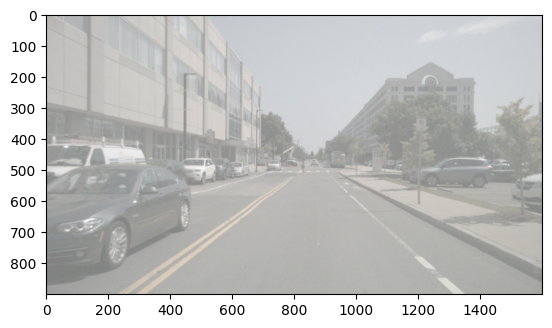

In [137]:
# 做对应object id 的 sam mask
# datadir = '/home/zyk/Projects/_DL/_Reconstruction/drivestudio/data/nuscenes/processed_10Hz/mini/001'

image_dir = os.path.join(datadir, 'images')
image_filenames_all = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))

num_cameras = len(cameras)
num_frames_all = len(image_filenames_all) // num_cameras
start_frame, end_frame = selected_frames[0], selected_frames[1]
num_frames = end_frame - start_frame + 1

intrinsics, extrinsics, ego_frame_poses, ego_cam_poses = load_camera_info_ds(datadir)
# colmap_basedir = os.path.join(f'/home/zyk/Projects/_DL/_Reconstruction/street_gaussians_new_start/output/waymo_full_exp_origin/0617_ds_nuscenes05_full/colmap')


frames = []
frames_idx = []
cams = []
image_filenames = []

ixts = []
exts = []
poses = []
c2ws = []

frames_timestamps = []
cams_timestamps = []

split_test = -1
split_train = -1
# train_frames, test_frames = get_val_frames(
#     num_frames, 
#     test_every=split_test if split_test > 0 else None,
#     train_every=split_train if split_train > 0 else None,
# )

# timestamp_path = os.path.join(datadir, 'timestamps.json')
# with open(timestamp_path, 'r') as f:
#     timestamps = json.load(f)

for frame in range(start_frame, end_frame+1):
#     frames_timestamps.append(timestamps['FRAME'][f'{frame:06d}'])
    frames_timestamps.append(frame)

for image_filename in image_filenames_all:
    image_basename = os.path.basename(image_filename)
    frame = image_filename_to_frame(image_basename)
    cam = image_filename_to_cam(image_basename)
    if frame >= start_frame and frame <= end_frame and cam in cameras:
        ixt = intrinsics[cam]
        ext = extrinsics[cam]
        # pose = ego_cam_poses[cam, frame]
        pose = ego_frame_poses[frame]
        # c2w = pose @ ext
        c2w = ego_cam_poses[cam, frame]

        frames.append(frame)
        frames_idx.append(frame - start_frame)
        cams.append(cam)
        image_filenames.append(image_filename)

        ixts.append(ixt)
        exts.append(ext)
        poses.append(pose)
        c2ws.append(c2w)

        # camera_name = _label2camera[cam]
        # timestamp = timestamps[camera_name][f'{frame:06d}']
        timestamp = frame
        cams_timestamps.append(timestamp)

exts = np.stack(exts, axis=0)
ixts = np.stack(ixts, axis=0)
poses = np.stack(poses, axis=0)
c2ws = np.stack(c2ws, axis=0)

# timestamp_offset = min(cams_timestamps + frames_timestamps)
timestamp_offset = 0
cams_timestamps = np.array(cams_timestamps) - timestamp_offset
frames_timestamps = np.array(frames_timestamps) - timestamp_offset
min_timestamp, max_timestamp = min(cams_timestamps.min(), frames_timestamps.min()), max(cams_timestamps.max(), frames_timestamps.max())




image_dir = os.path.join(datadir, 'images')
image_filenames_all = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))

num_cameras = len(cameras)
num_frames_all = len(image_filenames_all) // num_cameras
start_frame, end_frame = selected_frames[0], selected_frames[1]
num_frames = end_frame - start_frame + 1

intrinsics, extrinsics, ego_frame_poses, ego_cam_poses = load_camera_info_ds(datadir)    


ego_poses = ego_frame_poses


tracklets_ls = []    
objects_info = {}

frame_instances_path = os.path.join(datadir, 'instances/frame_instances.json')
instances_info_path = os.path.join(datadir, 'instances/instances_info.json')

with open(frame_instances_path, "r") as f:
    frame_instances = json.load(f)

with open(instances_info_path, "r") as f:
    instances_info = json.load(f)


start_frame, end_frame = selected_frames[0], selected_frames[1]

image_dir = os.path.join(datadir, 'images')
n_images = len(os.listdir(image_dir))
n_frames = n_images // num_cameras
n_obj_in_frame = np.zeros(n_frames)

for track_id_str in instances_info.keys():
    track_id = int(track_id_str)
    track_instance = instances_info[track_id_str]

    object_class = track_instance["class_name"]
    if "vehicle" in object_class:
        object_class = "vehicle"
    elif "pedestrian" in object_class:
        object_class = "pedestrian"

    if track_id not in objects_info.keys():
        objects_info[track_id] = dict()
        objects_info[track_id]['track_id'] = track_id
        objects_info[track_id]['class'] = object_class 
        objects_info[track_id]['class_label'] = waymo_track2label[object_class]
        objects_info[track_id]['height'] = track_instance["frame_annotations"]["box_size"][0][2]
        objects_info[track_id]['width'] = track_instance["frame_annotations"]["box_size"][0][1]
        objects_info[track_id]['length'] = track_instance["frame_annotations"]["box_size"][0][0]

    else:
        objects_info[track_id]['height'] = max(objects_info[track_id]['height'], track_instance["frame_annotations"]["box_size"][0][2])
        objects_info[track_id]['width'] = max(objects_info[track_id]['width'], track_instance["frame_annotations"]["box_size"][0][1])
        objects_info[track_id]['length'] = max(objects_info[track_id]['length'], track_instance["frame_annotations"]["box_size"][0][0])

tracklets_array = np.array(tracklets_ls)
max_obj_per_frame = int(n_obj_in_frame[start_frame:end_frame + 1].max())
num_frames = end_frame - start_frame + 1
visible_objects_ids = np.ones([num_frames, max_obj_per_frame]) * -1.0
visible_objects_pose_vehicle = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0
visible_objects_pose_world = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0

for frame_id in frame_instances.keys():
    n_obj_in_frame[int(frame_id)] = len(frame_instances[frame_id])

num_frames = end_frame - start_frame + 1
max_obj_per_frame = int(n_obj_in_frame[start_frame:end_frame + 1].max())



visible_objects_ids = np.ones([num_frames, max_obj_per_frame]) * -1.0
visible_objects_pose_vehicle = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0
visible_objects_pose_world = np.ones([num_frames, max_obj_per_frame, 7]) * -1.0


lidar_to_world_start = np.loadtxt(os.path.join(datadir, 'lidar_pose', "000.txt"))
for k, v in instances_info.items():
    track_id = int(k)

    for frame_id, obj_to_world, box_size in zip(v["frame_annotations"]["frame_idx"], v["frame_annotations"]["obj_to_world"], v["frame_annotations"]["box_size"]):
    # 此处frame是时间而非帧 

# ################# 此处 DS所用ID track_id，与 STG所用ID tracklet_camera_vis是不一致的。
#         cameras_vis_list = tracklet_camera_vis[str(track_id)][str(frame_id)]
#         join_cameras_list = list(set(cameras) & set(cameras_vis_list))
#         if len(join_cameras_list) == 0:
#             continue
# ####################
        if start_frame <= frame_id <= end_frame:            

            frame_idx = frame_id - start_frame

            # ego_to_world_start = np.loadtxt(os.path.join(datadir, "ego_pose", f"{frame_idx:03d}.txt"))

            obj_pose_world_mat = np.array(obj_to_world).reshape(4, 4)
            obj_pose_world_mat = np.linalg.inv(lidar_to_world_start) @ obj_pose_world_mat

            ego_pose_world = ego_frame_poses[frame_id]
            obj_pose_vehicle, obj_pose_world = make_obj_pose_ds(ego_pose_world, obj_pose_world_mat)

            obj_column = np.argwhere(visible_objects_ids[frame_idx, :] < 0).min()

            visible_objects_ids[frame_idx, obj_column] = track_id
            visible_objects_pose_vehicle[frame_idx, obj_column] = obj_pose_vehicle
            visible_objects_pose_world[frame_idx, obj_column] = obj_pose_world


# Remove static objects
print("Removing static objects")
for key in objects_info.copy().keys():
    all_obj_idx = np.where(visible_objects_ids == key)
    if len(all_obj_idx[0]) > 0:
        obj_world_postions = visible_objects_pose_world[all_obj_idx][:, :3]
        distance = np.linalg.norm(obj_world_postions[0] - obj_world_postions[-1])
        dynamic = np.any(np.std(obj_world_postions, axis=0) > 0.5) or distance > 2
        if not dynamic:
            visible_objects_ids[all_obj_idx] = -1.
            visible_objects_pose_vehicle[all_obj_idx] = -1.
            visible_objects_pose_world[all_obj_idx] = -1.
            objects_info.pop(key)
    else:
        objects_info.pop(key)

# Clip max_num_obj
mask = visible_objects_ids >= 0
max_obj_per_frame_new = np.sum(mask, axis=1).max()
print("Max obj per frame:", max_obj_per_frame_new)

if max_obj_per_frame_new == 0:
    print("No moving obj in current sequence, make dummy visible objects")
    visible_objects_ids = np.ones([num_frames, 1]) * -1.0
    visible_objects_pose_world = np.ones([num_frames, 1, 7]) * -1.0
    visible_objects_pose_vehicle = np.ones([num_frames, 1, 7]) * -1.0    
elif max_obj_per_frame_new < max_obj_per_frame:
    visible_objects_ids_new = np.ones([num_frames, max_obj_per_frame_new]) * -1.0
    visible_objects_pose_vehicle_new = np.ones([num_frames, max_obj_per_frame_new, 7]) * -1.0
    visible_objects_pose_world_new = np.ones([num_frames, max_obj_per_frame_new, 7]) * -1.0
    for frame_idx in range(num_frames):
        for y in range(max_obj_per_frame):
            obj_id = visible_objects_ids[frame_idx, y]
            if obj_id >= 0:
                obj_column = np.argwhere(visible_objects_ids_new[frame_idx, :] < 0).min()
                visible_objects_ids_new[frame_idx, obj_column] = obj_id
                visible_objects_pose_vehicle_new[frame_idx, obj_column] = visible_objects_pose_vehicle[frame_idx, y]
                visible_objects_pose_world_new[frame_idx, obj_column] = visible_objects_pose_world[frame_idx, y]

    visible_objects_ids = visible_objects_ids_new
    visible_objects_pose_vehicle = visible_objects_pose_vehicle_new
    visible_objects_pose_world = visible_objects_pose_world_new

box_scale =1.5
print('box scale: ', box_scale)

frames = list(range(start_frame, end_frame + 1))
frames = np.array(frames).astype(np.int32)

# postprocess object_info   
for key in objects_info.keys():
    obj = objects_info[key]
    if obj['class'] == 'Pedestrian':
        obj['deformable'] = True
    else:
        obj['deformable'] = False

    obj['width'] = obj['width'] * box_scale
    obj['length'] = obj['length'] * box_scale

    obj_frame_idx = np.argwhere(visible_objects_ids == key)[:, 0]
    obj_frame_idx = obj_frame_idx.astype(np.int32)
    obj_frames = frames[obj_frame_idx]
    obj['start_frame'] = np.min(obj_frames)
    obj['end_frame'] = np.max(obj_frames)

    objects_info[key] = obj

# [num_frames, max_obj, track_id, x, y, z, qw, qx, qy, qz]
objects_tracklets_world = np.concatenate(
    [visible_objects_ids[..., None], visible_objects_pose_world], axis=-1
)

objects_tracklets_vehicle = np.concatenate(
    [visible_objects_ids[..., None], visible_objects_pose_vehicle], axis=-1
)

object_tracklets_vehicle = objects_tracklets_vehicle
object_info = objects_info



for current_view in tqdm(range(len(image_filenames))):
#     current_view = 172*num_cameras+0
    current_view = 55*num_cameras+0
    frame_id = current_view // len(cameras) 

    image = cv2.imread(image_filenames[current_view])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    predictor.set_image(image)
    image = 255-(255-image) // 2

    ixt = ixts[current_view]

    seg_result = np.ones([image.shape[0], image.shape[1], 3], dtype=np.int16) * 255
    seg_depth = np.zeros([image.shape[0], image.shape[1]])
    
    for vehicle_name in object_tracklets_vehicle[frame_id][:,0].astype(np.int16):
#         vehicle_name=12
        input_box = None
#         if vehicle_name == -1:
#             continue
        for vehicle_id in range(object_tracklets_vehicle[frame_id].shape[0]):
            tracklet = object_tracklets_vehicle[frame_id][vehicle_id]
            track_id = int(tracklet[0])
            if track_id==vehicle_name:
                break
        
        _ply_path = colmap_basedir.replace("colmap", "input_ply/points3D_obj_%.3d.ply"%vehicle_name)
        if not os.path.exists(_ply_path):
            continue
        
        plydata = PlyData.read(_ply_path)
        vertices = plydata['vertex']
        obj_positions = np.vstack([vertices['x'], vertices['y'], vertices['z']]).T
        obj_colors = np.vstack([vertices['red'], vertices['green'], vertices['blue']]).T / 255.0
        obj_normals = np.vstack([vertices['nx'], vertices['ny'], vertices['nz']]).T

#         _mask_a = obj_normals[:,1] * obj_positions[:,1] > 0 # 指向y中轴面
#         _mask_gnd = np.logical_and(obj_normals[:,2] > 0.9, obj_positions[:,2] < 0) # 指向z中轴面(直接剔除地面)
#         gnd_height = obj_positions[:, 2].min() + (obj_positions[_mask_gnd, 2].mean() - obj_positions[:, 2].min()) * 2
#         _mask_b = np.logical_or(obj_positions[:,2] > gnd_height, obj_normals[:,2] < 0.7)
#         mask_right_direction = np.logical_and(_mask_a, _mask_b)
        
        obj_pose_vehicle = np.eye(4)   
        obj_pose_vehicle[:3, :3] = quaternion_to_matrix_numpy(tracklet[4:8])
        obj_pose_vehicle[:3, 3] = tracklet[1:4]
        vehicle2local = np.linalg.inv(obj_pose_vehicle)

        ego_pose = ego_frame_poses[frame_id + selected_frames[0]]
#         points_normal_obj_world = obj_normals @ np.linalg.inv(vehicle2local[:3,:3]).T @ ego_pose[:3,:3].T

        obj_positions_local = np.concatenate([obj_positions, np.ones_like(obj_positions[..., :1])], axis=-1)
        points_xyz_obj_world = obj_positions_local @ obj_pose_vehicle.T @ ego_pose.T 

        ################################
        obj_visibility = np.load(colmap_basedir.replace("colmap", "input_ply/points3D_obj_%.3d.npy"%vehicle_name))
#         obj_visibility = np.load("/home/zyk/Projects/_DL/_Reconstruction/street_gaussians_new_start/output/waymo_full_exp_origin/waymo_train_021_0519_5cam/input_ply/points3D_obj_%.3d.npy"%vehicle_name)
        obj_view_mask = obj_visibility[:, current_view]
#         if obj_view_mask.sum() > 0:
#             print("1")
#             break
#         obj_colors[~obj_view_mask] = np.array([0.9,0.9,0.9])
#         obj_colors[obj_view_mask] = np.array([0,0,1])

#         view_pos_world = np.concatenate([points_xyz_obj_world[obj_view_mask,:3], np.ones_like(points_xyz_obj_world[obj_view_mask,:1])], axis=-1)
        view_pos_world = np.concatenate([points_xyz_obj_world[:,:3], np.ones_like(points_xyz_obj_world[:,:1])], axis=-1)
        view_pos_cam = view_pos_world @ np.linalg.inv(c2ws[current_view]).T

        tmp = view_pos_cam[:,:3] @ ixt.T
        us = tmp[:,0] / tmp[:,2]
        vs = tmp[:,1] / tmp[:,2]        

#       直接转换int数值溢出，可能导致视野外低深度obj生成无穷mask
#         mask = np.logical_and(us >= 0, us < image.shape[1])
#         mask = np.logical_and(mask, vs >= 0)
#         mask = np.logical_and(mask, vs < image.shape[0])

        us[us < -1] = -1
        us[us > image.shape[1]] = image.shape[1] + 1
        vs[vs < -1] = -1
        vs[vs > image.shape[0]] = image.shape[0] + 1
    
        us = us.astype(np.int16)
        vs = vs.astype(np.int16)
        
        
        mask = np.logical_and(us >= 0, us < image.shape[1])
#         mask = np.logical_and(mask, us < image.shape[1])
        mask = np.logical_and(mask, vs >= 0)
        mask = np.logical_and(mask, vs < image.shape[0])
        mask = np.logical_and(mask, tmp[:,2] > 0.1)
            
        if mask.sum() < 20:
            print("insufficient point")
            continue

        if tmp[:,2].max() < 0.2:
            continue
    
        print("vehicle_name", vehicle_name)

        us_valid = us[mask]
        vs_valid = vs[mask]
        num_valid = len(us_valid)
        
        SW = 2
        if SW == 0:
            k = max(int(0.005 * num_valid), 1)
            u_min_10 = np.partition(us_valid, k - 1)[k]        # 前 k 小
            u_max_10 = np.partition(us_valid, -k)[-k]          # 后 k 大
            v_min_10 = np.partition(vs_valid, k - 1)[k]        # 前 k 小
            v_max_10 = np.partition(vs_valid, -k)[-k]          # 后 k 大
            input_box = np.array([u_min_10, v_min_10, u_max_10, v_max_10])
        elif SW == 1:
            k = max(int(0.005 * us.shape[0]), 1)
            u_min_10 = np.partition(us, k - 1)[k]        # 前 k 小
            u_max_10 = np.partition(us, -k)[-k]          # 后 k 大
            v_min_10 = np.partition(vs, k - 1)[k]        # 前 k 小
            v_max_10 = np.partition(vs, -k)[-k]          # 后 k 大
            
            u_min_10 = max(u_min_10, 0)
            u_max_10 = min(u_max_10, image.shape[1]-1)
            v_min_10 = max(v_min_10, 0)
            v_max_10 = min(v_max_10, image.shape[0]-1)
            input_box = np.array([u_min_10, v_min_10, u_max_10, v_max_10])

        else:
            input_box = np.array([us[mask].min(), vs[mask].min(), us[mask].max(), vs[mask].max()])
        

        masks, scores, logits = predictor.predict(
            point_coords=None,
            point_labels=None,
            box=input_box[None, :],
            multimask_output=True,
        )
        
        if masks.shape[0] == 0 or scores.max() < 0.9:
            continue
            
        m = masks[scores.argmax()]
            
        if (seg_result[m, 0] != 255).sum() < 10:
            seg_result[m, 0] = track_id
        elif (seg_result[m, 1] != 255).sum() < 10:
            seg_result[m, 1] = track_id
        elif (seg_result[m, 2] != 255).sum() < 10:
            seg_result[m, 2] = track_id
        else:
            print("confliction: ", vehicle_name, (seg_result[m, :] != 255).sum())
            
        
        
        
#         seg_depth[np.where(masks[0])[0][to_replace], np.where(masks[0])[1][to_replace]] = tmp[:,2].mean()
#         for i, (_mask, score) in enumerate(zip(masks, scores)):
#             plt.figure(figsize=(10,10))
#             image[vs[mask], us[mask], 0] = 255
#             image[vs[mask], us[mask], 1] = 0
#             image[vs[mask], us[mask], 2] = 0
#             plt.imshow(image)
#             show_mask(_mask, plt.gca())
#         #     show_points(input_point, input_label, plt.gca())
#             show_box(input_box, plt.gca())
#             plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
#             plt.axis('off')
#             plt.show()  
#         if input_box is not None:
#             break
#     cv2.imwrite(image_filenames[current_view].replace("images", "sam_masks").replace(".jpg", ".png"), seg_result)
#         break
    break
    
plt.imshow(image)
object_tracklets_vehicle[frame_id][:,0].astype(np.int16)

In [122]:
obj_visibility.shape

(1403, 305)

(4632,)

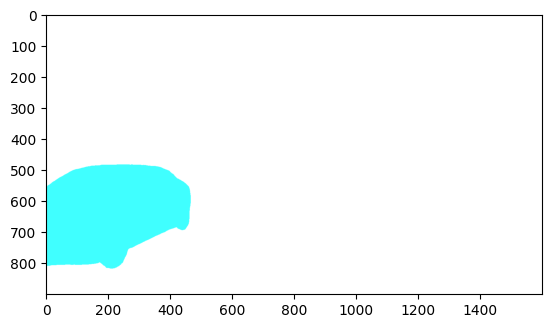

In [138]:
plt.imshow(seg_result)
us[mask].shape

In [ ]:
vs_valid

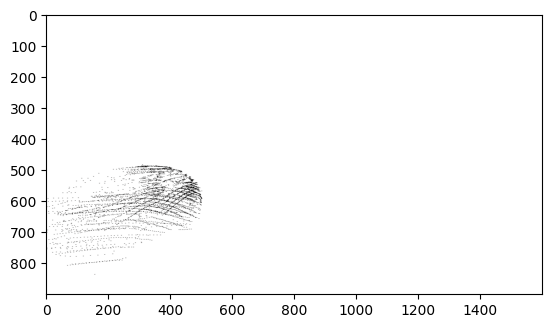

In [139]:
tmp = np.ones_like(image) * 255

tmp[vs_valid, us_valid, 0] = 1
tmp[vs_valid, us_valid, 1] = 0
tmp[vs_valid, us_valid, 2] = 0

tmp[vs_valid, us_valid+1, 0] = 1
tmp[vs_valid, us_valid+1, 1] = 0
tmp[vs_valid, us_valid+1, 2] = 0

tmp[vs_valid, us_valid-1, 0] = 1
tmp[vs_valid, us_valid-1, 1] = 0
tmp[vs_valid, us_valid-1, 2] = 0

plt.imshow(tmp)


In [ ]:
vs_valid.shape

In [87]:
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(view_pos_cam[:,:3])                
o3d.visualization.draw_geometries([pcd, FOR1], point_show_normal=True)

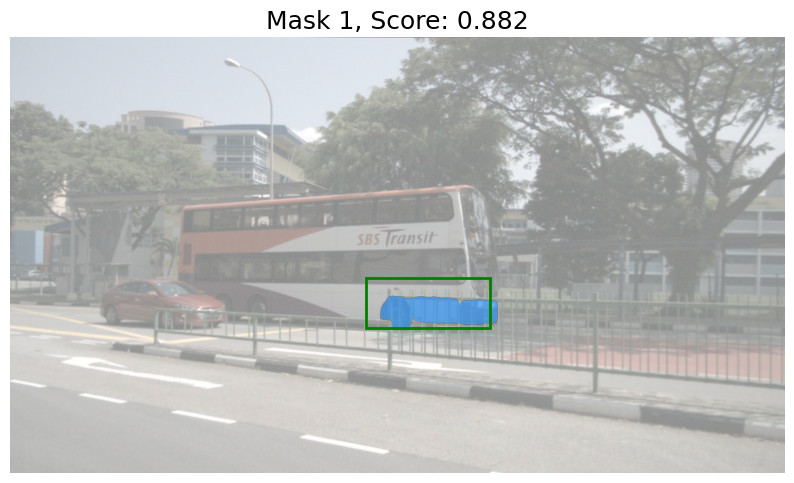

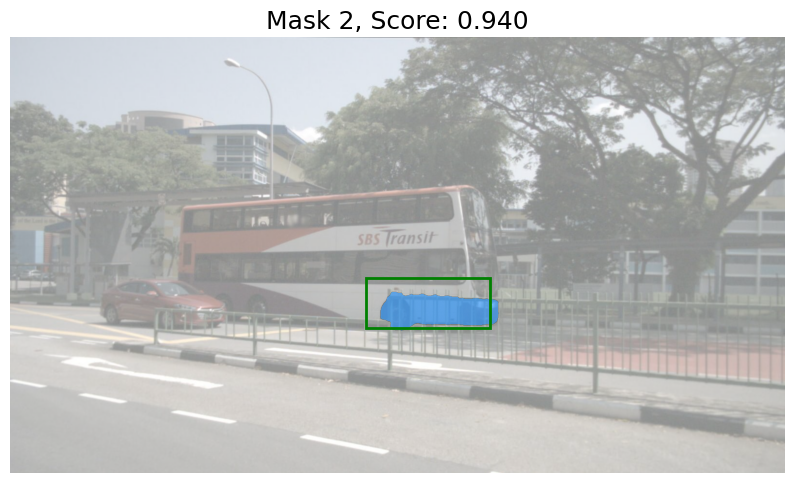

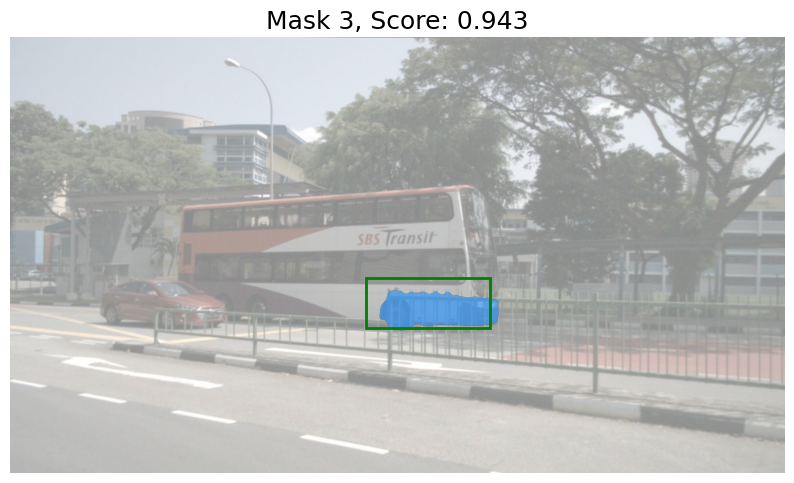

In [86]:
    
def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))    


def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)

for i, (_mask, score) in enumerate(zip(masks, scores)):
    plt.figure(figsize=(10,10))
    plt.imshow(image)
    show_mask(_mask, plt.gca())
#     show_points(input_point, input_label, plt.gca())
    show_box(input_box, plt.gca())
    plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
    plt.axis('off')
    plt.show()  

In [ ]:
obj_ply_path = colmap_basedir.replace("colmap", "input_ply/points3D_obj_005.ply")
plydata = PlyData.read(obj_ply_path)
vertices = plydata['vertex']

obj_positions = np.vstack([vertices['x'], vertices['y'], vertices['z']]).T
obj_positions_local = np.concatenate([obj_positions, np.ones([obj_positions.shape[0], 1])], axis=1)

obj_colors = np.vstack([vertices['red'], vertices['green'], vertices['blue']]).T / 255.0
obj_normals = np.vstack([vertices['nx'], vertices['ny'], vertices['nz']]).T

my_vis(obj_positions, obj_colors, obj_normals, coord_size=1)

In [ ]:
# 可视化地图对齐。 Q:是否能判断mask

normal_lines = []
line_colors = []
# tmp = points_xyz_vehicle[mask_cam] @ ego_pose.T
tmp = bkgd_positions[:,:3]

pcd = o3d.geometry.PointCloud()
# _p = obj_positions_local @ obj_pose_vehicle.T @ ego_pose.T 
_p = obj_positions_local @ obj_pose_vehicle.T
# _p = _p @ ego_pose.T 
pcd.points = o3d.utility.Vector3dVector(_p[:,:3])               
_c = np.zeros(points_xyz_obj_world[:,:3].shape)
_c[: ,0] = 1
pcd.colors = o3d.utility.Vector3dVector(_c)

FOR1 = o3d.geometry.TriangleMesh.create_coordinate_frame(size=30, origin=[0, 0, 0])


# p1 = tmp
# p2 = tmp + bkgd_normals * 0.2
# normal_lines = np.concatenate([p1, p2], axis=1).reshape(-1, 3)
# line_colors = np.zeros([p1.shape[0], 3]).astype(np.int8)
# line_colors[:, 0] = 1


# line_set = o3d.geometry.LineSet()
# line_set.points = o3d.utility.Vector3dVector(normal_lines)
# line_set.lines = o3d.utility.Vector2iVector(np.arange(p1.shape[0] * 2).reshape(-1, 2))
# line_set.colors = o3d.utility.Vector3dVector(line_colors)


bkgd_pcd = o3d.geometry.PointCloud()
pb_l =  bkgd_positions @ np.linalg.inv(ego_pose.T)
bkgd_pcd.points = o3d.utility.Vector3dVector(pb_l[:,:3])                
bkgd_pcd.colors = o3d.utility.Vector3dVector(bkgd_colors)


# o3d.visualization.draw_geometries([pcd, FOR1], point_show_normal=True)

o3d.visualization.draw_geometries([bkgd_pcd, pcd, FOR1], point_show_normal=True)
# o3d.visualization.draw_geometries([pcd, line_set, FOR1], point_show_normal=True)

In [ ]:
o3d.visualization.draw_geometries([pcd, FOR1], point_show_normal=True)


In [ ]:
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
sam_checkpoint = "/home/zyk/Projects/_DL/_Segment/segment-anything/sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(sam)

def show_anns(anns):
    if len(anns) == 0:
        return
    
    if len(anns) > 255:
        print("TOO MANY LABELS")
        
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=False)
#     ax = plt.gca()
#     ax.set_autoscale_on(False)

    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:,:,3] = 0

    res = np.zeros((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1]), dtype=np.int32)
    cnt = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m] = color_mask
        
        res[m] = cnt
        cnt += 1
#     ax.imshow(img)
    return res

In [ ]:
images_for_sam_all = []

for i in [5]:
    _d = f"/home/zyk/Projects/_DL/_Reconstruction/drivestudio/data/nuscenes/processed_10Hz/mini/{i:03d}"
    images_for_sam_all += sorted(glob.glob(os.path.join(_d, "images", '*.jpg')))

# images_for_sam_all

In [ ]:
# 只将bkgd 分解为区域小块（唯一要求是同时包含root和vine），用以判别缺失
from tqdm import tqdm

# current_view = 60
for current_view in tqdm(range(len(images_for_sam_all))):
    _path = images_for_sam_all[current_view]
    
    image = cv2.imread(_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    masks = mask_generator.generate(image)
    res = show_anns(masks)

    new_res = np.zeros(res.shape)
    cnt = 1
    for c in np.unique(res):
        new_res[res==c] = cnt
        cnt += 1
    
    if cnt >= 255:
        print("larger than 255, idx ", current_view)
    cv2.imwrite(_path.replace("images", "sam_bkgd_masks").replace(".jpg", ".png"), new_res)
#     break


In [ ]:
plt.imshow(res)

In [ ]:
# 检查render_kernel的问题：

from plyfile import PlyData, PlyElement

colmap_basedir = os.path.join(f'/home/zyk/Projects/_DL/_Reconstruction/street_gaussians_new_start/output/waymo_full_exp_origin/0617_ds_nuscenes05/colmap')


for obj_ply_path in glob.glob(colmap_basedir.replace("colmap", "input_ply/*obj*.ply")):

    plydata = PlyData.read(obj_ply_path)
    vertices = plydata['vertex']

    obj_positions = np.vstack([vertices['x'], vertices['y'], vertices['z']]).T
    obj_positions = np.concatenate([obj_positions, np.ones([obj_positions.shape[0], 1])], axis=1)

    obj_colors = np.vstack([vertices['red'], vertices['green'], vertices['blue']]).T / 255.0
    obj_normals = np.vstack([vertices['nx'], vertices['ny'], vertices['nz']]).T

    obj_vis = np.load(obj_ply_path.replace(".ply", ".npy"))
    print(obj_positions, obj_colors, obj_normals, obj_vis)
    
#     obj_ply_path, obj_colors, obj_normals

In [ ]:
for path in glob.glob(os.path.join(data_path, "normal_img/*.png")):
    normal = plt.imread(path)
    if np.isnan(normal).sum() > 0:
        print(path)